In [1]:
# Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns
from ucimlrepo import fetch_ucirepo 
  


# 1) Data Loading and Business Understanding

In [2]:
# Fetch dataset 

statlog_german_credit_data = fetch_ucirepo(id=144) 

columns = [
    'status_checking', 'duration_months', 'credit_history', 'purpose',
    'credit_amount', 'savings', 'employment_since', 'installment_rate',
    'personal_status_sex', 'other_debtors', 'residence_since', 'property',
    'age', 'other_installment_plans', 'housing', 'existing_credits',
    'job', 'people_liable', 'telephone', 'foreign_worker', 'target'
]

df = statlog_german_credit_data.data.original
df.columns = columns

print("Number of rows:", df.shape[0])
print("Number of colums:",df.shape[1])


# Target Distribution

target_distribution = df['target'].map(
    {
        1:"Good",
        2:"Bad"
    }
).value_counts()
print("Good VS Bad Targets:\n", target_distribution)

print("First 5 rows:\n", df.head(5))


Number of rows: 1000
Number of colums: 21
Good VS Bad Targets:
 target
Good    700
Bad     300
Name: count, dtype: int64
First 5 rows:
   status_checking  duration_months credit_history purpose  credit_amount  \
0             A11                6            A34     A43           1169   
1             A12               48            A32     A43           5951   
2             A14               12            A34     A46           2096   
3             A11               42            A32     A42           7882   
4             A11               24            A33     A40           4870   

  savings employment_since  installment_rate personal_status_sex  \
0     A65              A75                 4                 A93   
1     A61              A73                 2                 A92   
2     A61              A74                 2                 A93   
3     A61              A74                 2                 A93   
4     A61              A73                 3                 A93   

### Business Interpretation

A **default / bad risk** is a borrower who is likely to fail to repay a loan according to the agreed terms.
In a bank context, identifying bad-risk customers helps reduce financial losses from unpaid loans.
A **false negative** occurs when a customer who is actually a bad risk is incorrectly classified as good.
False negatives are especially costly because the bank may approve a loan that later defaults.
A **false positive** occurs when a good customer is incorrectly classified as a bad risk and their loan is rejected.
Therefore, the bank must balance the cost of missed bad risks with the cost of rejecting creditworthy customers.

# 2) Data Quality and Simple EDA

Number of Missing Values: status_checking            0
duration_months            0
credit_history             0
purpose                    0
credit_amount              0
savings                    0
employment_since           0
installment_rate           0
personal_status_sex        0
other_debtors              0
residence_since            0
property                   0
age                        0
other_installment_plans    0
housing                    0
existing_credits           0
job                        0
people_liable              0
telephone                  0
foreign_worker             0
target                     0
dtype: int64
Numerical Features:
 ['duration_months', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'people_liable', 'target']
Categorical Features:
 ['status_checking', 'credit_history', 'purpose', 'savings', 'employment_since', 'personal_status_sex', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', '

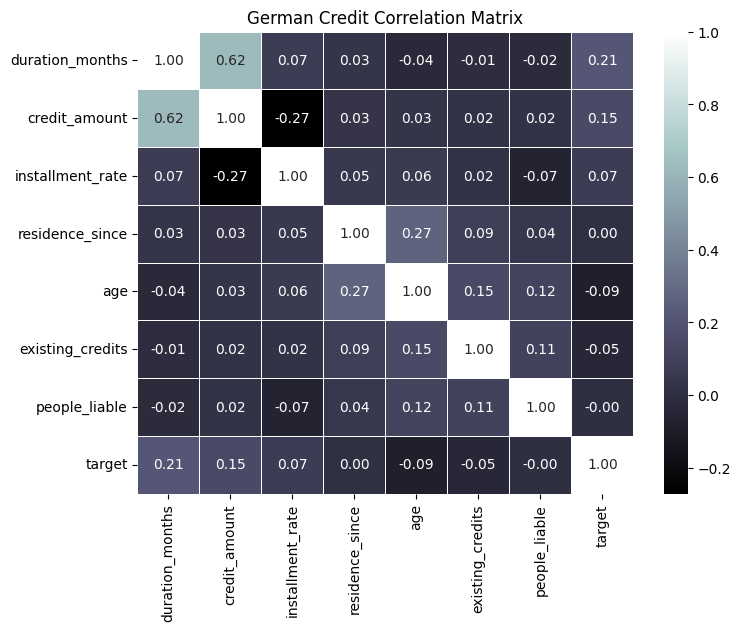

Top-3 Features Most Correlated with Target:
 target             1.000000
duration_months    0.214927
credit_amount      0.154739
age                0.091127
Name: target, dtype: float64


In [3]:
# Missing Values

missing_values = df.isnull().sum()
print("Number of Missing Values:", missing_values)

# Numeric Features

numerical_features = df.select_dtypes(include=np.number).columns.tolist()
print('Numerical Features:\n',numerical_features)

# Categorical Features

categorical_features = df.select_dtypes(include=object).columns.tolist()
print("Categorical Features:\n",categorical_features)

# Correlation Matrix

matrix = df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(8,6))
sns.heatmap(matrix , annot=True, cmap='bone',fmt='.2f', linewidths=0.5)
plt.title("German Credit Correlation Matrix")
plt.show()

# Top-3 numeric features

top_three = matrix['target'].abs().nlargest(4)
print("Top-3 Features Most Correlated with Target:\n",top_three)


# 3) Preprocessing

In [4]:
# Train / Test(80/20)

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

X = df.drop('target' , axis=1)
y = df['target']

numerical_features = X.select_dtypes(include=np.number).columns
categorical_features = X.select_dtypes(include=object).columns

train_X , test_X , train_y, test_y = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", train_X.shape)
print("Testing set:", test_X.shape)

# Pipeline for numerical features
numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# Pipeline for categorical features
categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both preprocessing methods
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

Training set: (800, 20)
Testing set: (200, 20)


# 4) Build 3 Baseline Models (No Tuning)

Logistic Regression trained successfully.
Decision Tree trained successfully.
kNN trained successfully.
Logistic Regression
Accuracy:  0.7800
Precision: 0.6667
Recall:    0.5333
F1-score:  0.5926

Confusion Matrix:


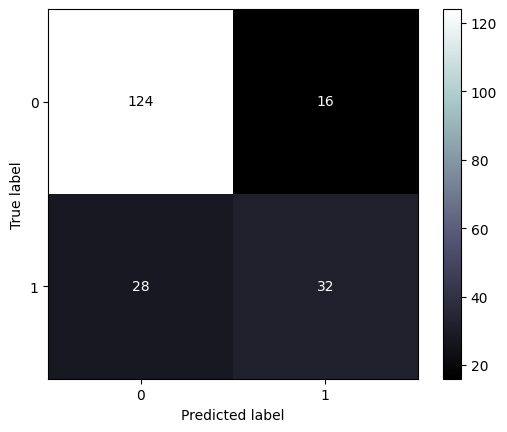

Decision Tree
Accuracy:  0.6650
Precision: 0.4407
Recall:    0.4333
F1-score:  0.4370

Confusion Matrix:


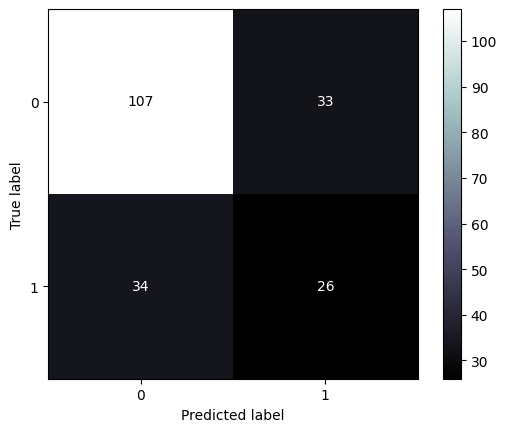

kNN
Accuracy:  0.7250
Precision: 0.5676
Recall:    0.3500
F1-score:  0.4330

Confusion Matrix:


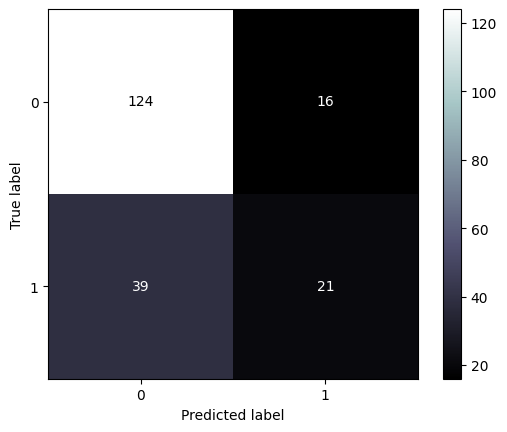

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import ConfusionMatrixDisplay

# Define the three models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42, criterion="entropy"),
    "kNN": KNeighborsClassifier()
}

# Create pipelines
pipelines = {}

for name, model in models.items():
    pipelines[name] = Pipeline([
        ('preprocessing', preprocessor),
        ('model', model)
    ])

# Train each model
for name, pipeline in pipelines.items():
    pipeline.fit(train_X, train_y)
    print(f"{name} trained successfully.")


from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

for name, pipeline in pipelines.items():
    
    # Predictions
    pred_y = pipeline.predict(test_X)
    
    # Metrics
    accuracy = accuracy_score(test_y, pred_y)
    precision = precision_score(test_y, pred_y, pos_label=2)
    recall = recall_score(test_y, pred_y, pos_label=2)
    f1 = f1_score(test_y, pred_y, pos_label=2)
    cm = confusion_matrix(test_y, pred_y)
    
    print(name)
    
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-score:  {f1:.4f}")
    
    print("\nConfusion Matrix:")
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap='bone')
    plt.show()

In **credit risk**, approving a bad client (**FN — False Negative**) is generally more costly for the bank than rejecting a good client (**FP — False Positive**).

* **FN:** The model predicts “Good,” but the client is actually “Bad.” The bank approves the loan, and the client may default, causing a **direct financial loss**.
* **FP:** The model predicts “Bad,” but the client is actually “Good.” The bank rejects the loan, so it **loses potential interest/profit** and may lose a good customer.
* Therefore, **FN is usually more serious from a credit-loss perspective**, while FP represents a missed business opportunity.
* However, the actual cost depends on the bank's risk policy, loan size, default probability, and the consequences of rejecting creditworthy customers.


# 5) Simple “Business Threshold”



Threshold = 0.65
Confusion Matrix:


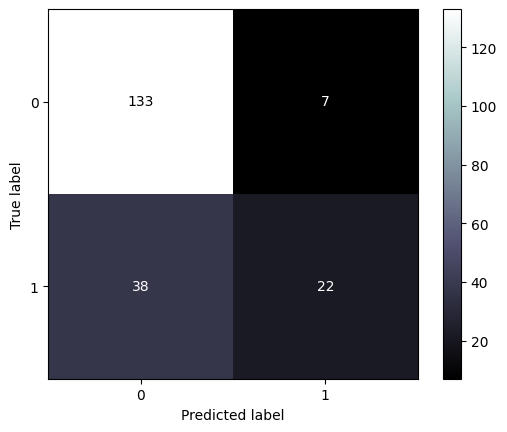

Accuracy: 0.7750
Precision: 0.7586
Recall:    0.3667
F1-score:  0.4944

Threshold = 0.5
Confusion Matrix:


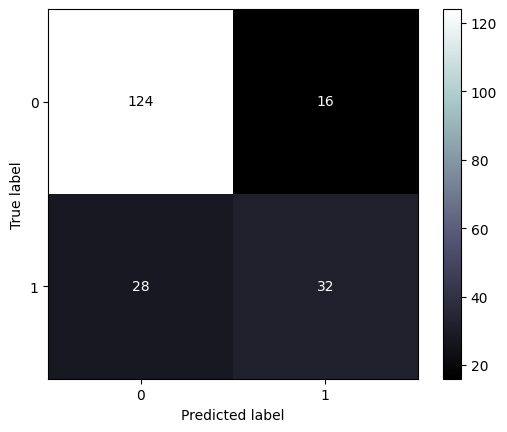

Accuracy: 0.7800
Precision: 0.6667
Recall:    0.5333
F1-score:  0.5926

Threshold = 0.35
Confusion Matrix:


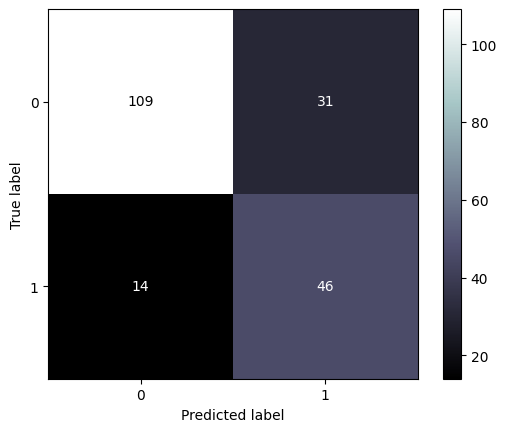

Accuracy: 0.7750
Precision: 0.5974
Recall:    0.7667
F1-score:  0.6715


In [6]:
# Probability of Bad class (target = 2)
prob_y = pipelines["Logistic Regression"].predict_proba(test_X)[:, 1]

thresholds = [0.65, 0.50, 0.35]

for threshold in thresholds:
    # Convert probability into class
    pred_y = (prob_y >= threshold).astype(int) + 1

    cm = confusion_matrix(test_y, pred_y)

    accuracy = accuracy_score(test_y , pred_y)
    precision = precision_score(test_y, pred_y, pos_label=2)
    recall = recall_score(test_y, pred_y, pos_label=2)
    f1 = f1_score(test_y, pred_y, pos_label=2)

    print(f"\nThreshold = {threshold}")
    print("Confusion Matrix:")
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap='bone')
    plt.show()
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-score:  {f1:.4f}")

### Business Threshold

**1. Which threshold do you recommend and why?**

I recommend a threshold of **0.35** because it has the highest recall (**0.7667**) and F1-score (**0.6715**). It also has the lowest number of false negatives (**14**), meaning fewer bad-risk clients are incorrectly approved.

**2. How does lowering the threshold change the number of rejected clients?**

Lowering the threshold increases the number of rejected clients. The model rejects **29 clients** at 0.65, **48 clients** at 0.50, and **77 clients** at 0.35.

**3. Which threshold reduces the number of bad clients approved?**

The **0.35 threshold** reduces the number of bad clients approved. It has only **14 false negatives**, compared with 28 at 0.50 and 38 at 0.65.

**4. Which threshold increases the number of good clients rejected?**

The **0.35 threshold** increases the number of good clients rejected. It has **31 false positives**, compared with 16 at 0.50 and 7 at 0.65.

**5. If you were the Head of Risk, which threshold would you recommend and why?**

I would recommend **0.35** if the main priority is to reduce the risk of approving bad clients. It provides the highest recall and the lowest number of false negatives. However, it also rejects more good clients, so this trade-off should be considered.


# 6) Production-Oriented task: “Manual Review Queue”


In [7]:
model = pipelines["Logistic Regression"]

# Probability of Bad class
prob_y = model.predict_proba(test_X)[:, 1]

def decision_zone(p):
    if p < 0.20:
        return "Auto-approve"
    elif p < 0.50:
        return "Manual review"
    else:
        return "Auto-reject"

decisions = [decision_zone(p) for p in prob_y]

decision_counts = pd.Series(decisions).value_counts()
print(decision_counts)

Auto-approve     91
Manual review    61
Auto-reject      48
Name: count, dtype: int64


### Business Interpretation

The three decision zones help reduce workload and manage credit risk. Low-risk clients with a probability below 0.20 are automatically approved, so employees do not need to review every application. High-risk clients with a probability of 0.50 or higher are automatically rejected. Clients with probabilities between 0.20 and 0.50 are sent for manual review because their risk is less certain.

This approach reduces the workload for bank employees by focusing manual review on borderline cases. At the same time, it helps manage risk by giving additional attention to clients whose probability of being a bad-risk customer is neither clearly low nor clearly high.


# 7) Business Demonstration

## Business Demo: Loan Approval Risk Model

### 1. Executive summary

- **Dataset:** the Statlog German Credit dataset (UCI) contains 1,000 past loan applicants described by 20 attributes (checking account status, loan duration and amount, credit history, savings, employment, age, housing, etc.). Each applicant is labelled **Good** (700) or **Bad** (300) credit risk. The data has no missing values.
- **Goal:** predict the probability that a new applicant will default, so the bank can approve safe loans quickly, avoid losses on risky ones, and spend analyst time only on unclear cases.
- **Best model chosen:** **Logistic Regression**. It was the strongest of the three baselines (Logistic Regression, Decision Tree, kNN) and is easy to explain to credit officers and auditors.
- **Key metric result:** at the recommended threshold the model catches **76.7% of bad applicants** (recall on the bad class; 46 of 60 in the test set), with an F1-score of **0.67** and overall accuracy of **77.5%**. For comparison, the same model at the default 0.50 cutoff caught only 53.3% of bad applicants.
- **Recommended threshold:** **0.35** on the probability of default. It cuts missed bad clients (false negatives) from 28 to 14, at the price of rejecting more good clients (false positives rise from 16 to 31). This trade-off is acceptable because approving a bad loan costs the bank more than turning away a good customer.
- **How the manual review queue works:** every application receives a default probability and is routed to one of three zones.

| Zone | Rule (probability of default) | Action | Test-set applicants |
|---|---|---|---|
| Auto-approve | below 0.20 | Approved with no human involvement | 91 (45.5%) |
| Manual review | 0.20 to 0.50 | Sent to a credit analyst for a decision | 61 (30.5%) |
| Auto-reject | 0.50 or above | Declined automatically | 48 (24.0%) |

  Only about 3 in 10 applications need a person, and the review band contains the 0.35 cutoff, so analysts look at exactly the applicants the model is least sure about.

### 2. Model comparison

All results are on the 200-applicant test set. "Recall (bad class)" is the share of truly bad applicants the model flags.

| Model | Accuracy | Recall (bad class) | F1 | Comment |
|---|---|---|---|---|
| Logistic Regression (threshold 0.50) | 0.7800 | 0.5333 | 0.5926 | Most accurate baseline, but it misses almost half of the bad applicants. |
| Decision Tree | 0.6650 | 0.4333 | 0.4370 | Weakest overall, with unstable and inaccurate predictions. |
| kNN | 0.7250 | 0.3500 | 0.4330 | Lets about two thirds of bad applicants through. |
| **Logistic Regression (threshold 0.35), chosen** | 0.7750 | **0.7667** | **0.6715** | Same accuracy as the default, but far better at catching bad clients. |

### 3. Confusion matrix of the chosen model
Logistic Regression at threshold 0.35 on the test set (rows are the true class, columns the model's decision).

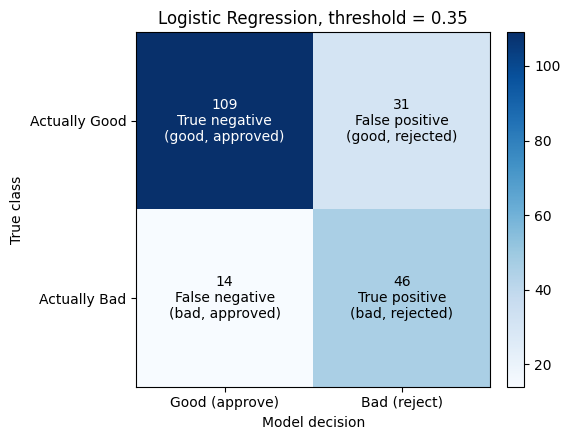

Bad clients caught: 46 of 60 (76.7%) | Good clients wrongly rejected: 31 of 140 (22.1%)


In [8]:
# --- Business demo: confusion matrix for the chosen model (Logistic Regression, threshold = 0.35)
BEST_THRESHOLD = 0.35

model = pipelines["Logistic Regression"]
prob_bad = model.predict_proba(test_X)[:, 1]              # probability of Bad (target = 2)
pred_best = (prob_bad >= BEST_THRESHOLD).astype(int) + 1  # 1 = Good, 2 = Bad

cm = confusion_matrix(test_y, pred_best, labels=[1, 2])
labels = ["Good (approve)", "Bad (reject)"]

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1], labels=labels)
ax.set_yticks([0, 1], labels=["Actually Good", "Actually Bad"])
ax.set_xlabel("Model decision")
ax.set_ylabel("True class")
ax.set_title(f"Logistic Regression, threshold = {BEST_THRESHOLD}")

cell_names = [["True negative\n(good, approved)", "False positive\n(good, rejected)"],
              ["False negative\n(bad, approved)", "True positive\n(bad, rejected)"]]
for i in range(2):
    for j in range(2):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, f"{cm[i, j]}\n{cell_names[i][j]}", ha="center", va="center",
                color=color, fontsize=10)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Bad clients caught: {tp} of {tp + fn} ({tp / (tp + fn):.1%}) | "
      f"Good clients wrongly rejected: {fp} of {tn + fp} ({fp / (tn + fp):.1%})")

### 4. Example: three applicants
One applicant is taken from each decision zone of the test set (the one with the median probability in that zone).

In [9]:
# --- Business demo: three example applicants, one per decision zone
from IPython.display import display, Markdown

prob_series = pd.Series(prob_bad, index=test_X.index)
zone_series = prob_series.apply(decision_zone)

checking_desc = {
    "A11": "an overdrawn checking account",
    "A12": "a low checking balance",
    "A13": "a healthy checking balance",
    "A14": "no checking account on file",
}

def explain(row, p, zone):
    profile = (f"a {row['duration_months']}-month loan of {row['credit_amount']:,} DM, "
               f"{checking_desc.get(row['status_checking'], 'an unknown account status')}, "
               f"age {row['age']}")
    if zone == "Auto-approve":
        return (f"Estimated default risk is only {p:.0%}, well below the 20% cutoff ({profile}). "
                f"Safe to approve automatically without using analyst time.")
    if zone == "Manual review":
        return (f"Estimated default risk of {p:.0%} sits in the grey area between 20% and 50% ({profile}). "
                f"An analyst should check income and documents before deciding.")
    return (f"Estimated default risk of {p:.0%} is at or above the 50% limit ({profile}). "
            f"Automatic rejection protects the bank from a likely loss.")

outcome_name = {1: "Good", 2: "Bad"}
lines = []
for n, zone in enumerate(["Auto-approve", "Manual review", "Auto-reject"], start=1):
    in_zone = prob_series[zone_series == zone].sort_values()
    idx = in_zone.index[len(in_zone) // 2]            # median-probability applicant in this zone
    row, p = test_X.loc[idx], prob_series.loc[idx]
    lines.append(
        f"**Applicant {n}** (test row {idx}) | Probability of default: **{p:.1%}** | "
        f"Decision zone: **{zone}** | Actual outcome: {outcome_name[test_y.loc[idx]]}\n\n"
        f"> {explain(row, p, zone)}\n"
    )
display(Markdown("\n".join(lines)))

**Applicant 1** (test row 412) | Probability of default: **9.1%** | Decision zone: **Auto-approve** | Actual outcome: Bad

> Estimated default risk is only 9%, well below the 20% cutoff (a 12-month loan of 2,292 DM, no checking account on file, age 42). Safe to approve automatically without using analyst time.

**Applicant 2** (test row 804) | Probability of default: **34.2%** | Decision zone: **Manual review** | Actual outcome: Good

> Estimated default risk of 34% sits in the grey area between 20% and 50% (a 12-month loan of 7,472 DM, a low checking balance, age 24). An analyst should check income and documents before deciding.

**Applicant 3** (test row 353) | Probability of default: **68.3%** | Decision zone: **Auto-reject** | Actual outcome: Bad

> Estimated default risk of 68% is at or above the 50% limit (a 12-month loan of 6,199 DM, an overdrawn checking account, age 28). Automatic rejection protects the bank from a likely loss.
